# Declared vs. measured: India's "open defecation free" status and what the national health survey found

Every Indian state declared its rural areas open defecation free (ODF) under the Swachh Bharat Mission by 2 October 2019. This notebook compares that declaration with what the independent National Family Health Survey (NFHS-5, 2019–21) measured in 704 districts, how much districts changed since NFHS-4 (2015–16), and whether districts that gained more sanitation also saw larger improvements in child health.

**Data:** district fact sheets published by the International Institute for Population Sciences (IIPS), extracted with `code/extract_pdfs.py`. See the README for sources and limitations.

**Run in Colab:** *Runtime → Run all*. The data file is downloaded from this repository automatically.

In [1]:
import os, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

DATA = "nfhs_district_fact_sheets.csv"
if not os.path.exists(DATA):  # e.g. in Colab: fetch the data file from the GitHub repository
    DATA = "https://raw.githubusercontent.com/aahwaankhullar-pixel/declared-vs-measured/main/nfhs_district_fact_sheets.csv"
SRC, OUT = DATA, "."
os.makedirs(f"{OUT}/figures", exist_ok=True); os.makedirs(f"{OUT}/results", exist_ok=True)
GREEN, RED, GREY, INK = "#2E5E3E", "#C62828", "#9E9E9E", "#333333"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": GREY, "axes.titlesize": 11})

## 1. Load the district data
Each row is one district fact sheet. `_5` columns are NFHS-5 (2019–21); `_4` columns are NFHS-4 (2015–16). NFHS-5 fieldwork in 13 states began in January 2020, entirely after the ODF declaration; those districts are flagged so the main result can be checked on them alone.

In [2]:
# ---------- 1. load the district panel (extracted from the official IIPS fact sheets) ----------
df = pd.read_csv(SRC)
NAMES = {"andaman_nicobar_island": "Andaman & Nicobar", "dadra_nagar_haveli_daman_diu": "Dadra & Nagar Haveli and Daman & Diu",
         "jammu_kashmir": "Jammu & Kashmir", "nct_of_delhi": "Delhi"}
df["State"] = df["state_folder"].map(lambda s: NAMES.get(s, s.replace("_", " ").title()))
df["District"] = df["district_folder"].str.replace("_", " ").str.title()
df = df.drop(columns=[c for c in df.columns if c.endswith("_small")] + ["state_folder", "district_folder"])
# NFHS-5 phase 2 states: fieldwork began in January 2020, i.e. entirely after the 2 Oct 2019 ODF declaration
# (dates as printed in each district fact sheet).
PHASE2 = {"Arunachal Pradesh", "Chhattisgarh", "Haryana", "Jharkhand", "Madhya Pradesh", "Delhi", "Odisha",
          "Puducherry", "Punjab", "Rajasthan", "Tamil Nadu", "Uttar Pradesh", "Uttarakhand"}
df["surveyed_after_declaration"] = df["State"].isin(PHASE2)
assert df.loc[df.surveyed_after_declaration, "State"].nunique() == len(PHASE2), "state name mismatch"
df = df[["State", "District", "surveyed_after_declaration"] + [c for c in df.columns if c not in ("State", "District", "surveyed_after_declaration")]]
df.to_csv(f"{OUT}/results/district_panel.csv", index=False)

## 2. How far is measured sanitation from the declaration?
If a district is open defecation free, close to everyone should be using a toilet. NFHS-5 reports the share of people using an *improved, unshared* facility, so it understates toilet access somewhat (see README).

In [3]:
# ---------- 2. how far is measured coverage from the ODF declaration? ----------
s5 = df["sanitation_5"].dropna()
gap = {
    "districts_with_nfhs5": int(s5.size),
    "median_nfhs5": round(float(s5.median()), 1),
    "share_below_50": round(float((s5 < 50).mean() * 100), 1),
    "share_below_70": round(float((s5 < 70).mean() * 100), 1),
    "share_90_plus": round(float((s5 >= 90).mean() * 100), 1),
    "n_below_50": int((s5 < 50).sum()),
}
pair = df.dropna(subset=["sanitation_4", "sanitation_5"]).copy()
pair["d_san"] = pair["sanitation_5"] - pair["sanitation_4"]
gap.update({
    "districts_both_rounds": int(len(pair)),
    "median_nfhs4": round(float(pair["sanitation_4"].median()), 1),
    "median_gain_pp": round(float(pair["d_san"].median()), 1),
    "share_gained_20pp_plus": round(float((pair["d_san"] >= 20).mean() * 100), 1),
    "share_declined": round(float((pair["d_san"] < 0).mean() * 100), 1),
})
p2 = df.loc[df.surveyed_after_declaration, "sanitation_5"].dropna()
gap.update({"phase2_districts": int(p2.size), "phase2_median_nfhs5": round(float(p2.median()), 1),
            "phase2_share_below_70": round(float((p2 < 70).mean() * 100), 1),
            "phase2_share_below_50": round(float((p2 < 50).mean() * 100), 1)})
b = np.polyfit(pair["sanitation_4"], pair["d_san"], 1)
gap["convergence_slope"] = round(float(b[0]), 3)  # gain per pp of baseline

# lowest districts
low = df.dropna(subset=["sanitation_5"]).nsmallest(10, "sanitation_5")[["State", "District", "sanitation_4", "sanitation_5"]]
low.to_csv(f"{OUT}/results/lowest_10_districts.csv", index=False)
state_tab = df.groupby("State").agg(districts=("sanitation_5", "size"),
                                    median_nfhs5=("sanitation_5", "median"),
                                    share_below_50=("sanitation_5", lambda x: (x.dropna() < 50).mean() * 100)).round(1)
state_tab = state_tab.sort_values("median_nfhs5")
state_tab.to_csv(f"{OUT}/results/by_state.csv")

In [4]:
print(json.dumps(gap, indent=1))
print(low.to_string(index=False))

{
 "districts_with_nfhs5": 704,
 "median_nfhs5": 73.7,
 "share_below_50": 8.1,
 "share_below_70": 41.8,
 "share_90_plus": 6.4,
 "n_below_50": 57,
 "districts_both_rounds": 572,
 "median_nfhs4": 46.2,
 "median_gain_pp": 22.7,
 "share_gained_20pp_plus": 59.1,
 "share_declined": 3.5,
 "phase2_districts": 363,
 "phase2_median_nfhs5": 72.8,
 "phase2_share_below_70": 44.1,
 "phase2_share_below_50": 7.4,
 "convergence_slope": -0.454
}
       State  District  sanitation_4  sanitation_5
 West Bengal  Puruliya          12.1          29.2
Chhattisgarh   Bijapur          22.1          30.6
       Bihar    Araria          13.8          32.2
       Bihar Madhepura          14.2          34.6
Chhattisgarh     Sukma           NaN          35.5
       Bihar    Purnia          14.9          35.6
     Gujarat     Dahod          20.6          35.9
   Karnataka  Gulbarga          30.2          36.5
       Bihar     Saran          27.1          37.2
   Karnataka    Yadgir          18.9          37.4


## 3. Did districts that gained more sanitation also gain more in child health?
First-difference regressions across districts: the change in each child-health indicator on the change in sanitation, first alone and then controlling for changes in electricity, drinking water, clean cooking fuel and women's schooling, with state fixed effects. Standard errors are clustered by state. These are associations, not causal effects.

In [5]:
# ---------- 3. did districts that gained more sanitation see bigger health gains? ----------
def ols_cluster(y, X, groups):
    """OLS with cluster-robust (CR1) standard errors. Returns coef, se, n."""
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    u = y - X @ beta
    G = np.unique(groups); n, k = X.shape
    meat = np.zeros((k, k))
    for g in G:
        idx = groups == g
        sg = X[idx].T @ u[idx]
        meat += np.outer(sg, sg)
    c = (len(G) / (len(G) - 1)) * ((n - 1) / (n - k))
    V = c * XtX_inv @ meat @ XtX_inv
    return beta, np.sqrt(np.diag(V)), n, len(G)

reg_rows = []
for outcome in ["diarrhoea", "stunted", "underweight"]:
    for spec in ["bivariate", "controls + state FE"]:
        cols = ["sanitation", outcome] + (["electricity", "water", "clean_fuel", "women_school10"] if spec != "bivariate" else [])
        need = [f"{c}_{r}" for c in cols for r in (4, 5)]
        m = df.dropna(subset=need).copy()
        dX = pd.DataFrame({f"d_{c}": m[f"{c}_5"] - m[f"{c}_4"] for c in cols})
        y = dX.pop(f"d_{outcome}").values
        X = dX
        if spec != "bivariate":
            X = pd.concat([X, pd.get_dummies(m["State"], drop_first=True, dtype=float)], axis=1)
        X.insert(0, "const", 1.0)
        beta, se, n, g = ols_cluster(y, X.values.astype(float), m["State"].values)
        j = list(X.columns).index("d_sanitation")
        reg_rows.append({"outcome": f"change in {outcome} (pp)", "specification": spec,
                         "coef_per_10pp_sanitation": round(beta[j] * 10, 2),
                         "ci95_low": round((beta[j] - 1.96 * se[j]) * 10, 2),
                         "ci95_high": round((beta[j] + 1.96 * se[j]) * 10, 2),
                         "districts": n, "state_clusters": g})
reg = pd.DataFrame(reg_rows)
reg.to_csv(f"{OUT}/results/regressions.csv", index=False)

# national context: health outcomes median change
for o in ["diarrhoea", "stunted", "underweight"]:
    p = df.dropna(subset=[f"{o}_4", f"{o}_5"])
    gap[f"median_change_{o}"] = round(float((p[f"{o}_5"] - p[f"{o}_4"]).median()), 1)
json.dump(gap, open(f"{OUT}/results/summary.json", "w"), indent=1)

In [6]:
print(reg.to_string(index=False))

                   outcome       specification  coef_per_10pp_sanitation  ci95_low  ci95_high  districts  state_clusters
  change in diarrhoea (pp)           bivariate                     -0.69     -1.66       0.28        572              32
  change in diarrhoea (pp) controls + state FE                      0.16     -0.57       0.89        572              32
    change in stunted (pp)           bivariate                     -1.26     -2.01      -0.52        572              32
    change in stunted (pp) controls + state FE                     -0.24     -1.04       0.55        572              32
change in underweight (pp)           bivariate                     -1.45     -2.42      -0.49        572              32
change in underweight (pp) controls + state FE                     -0.23     -1.09       0.64        572              32


## 4. Figures

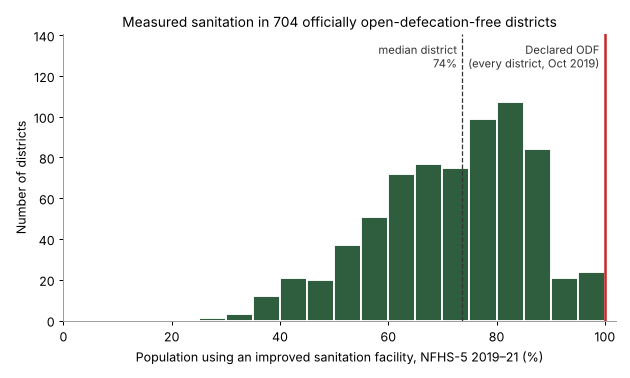

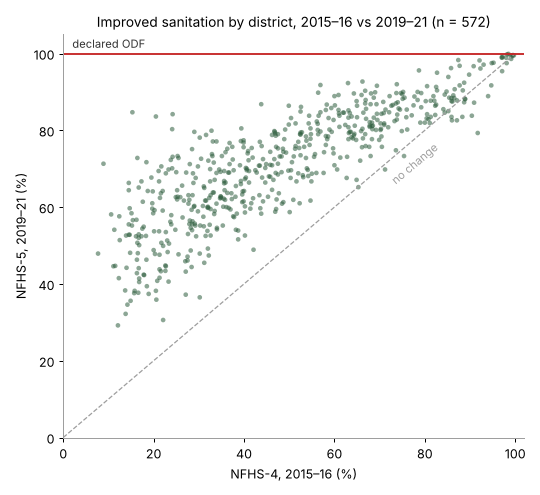

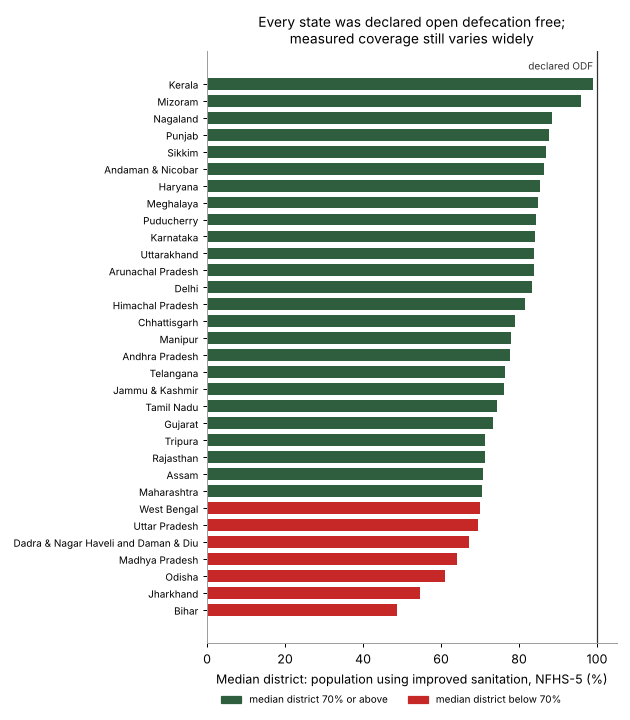

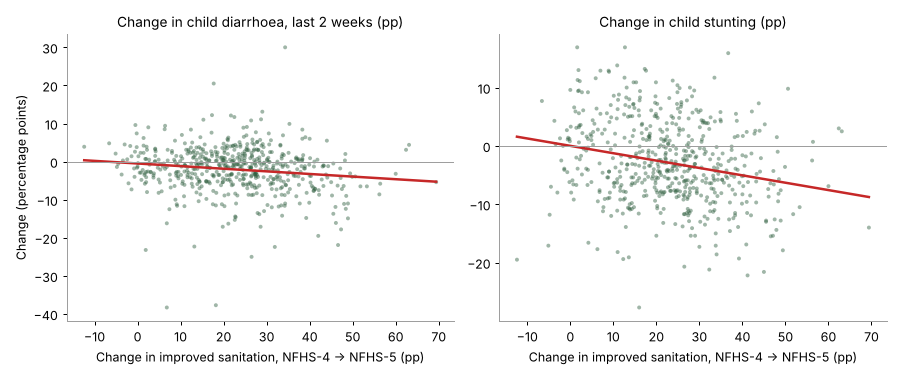

In [7]:
# ---------- 4. figures ----------
# Fig A: distribution of district coverage vs the 100% implied by ODF status
fig, ax = plt.subplots(figsize=(7, 4.2))
bins = np.arange(0, 105, 5)
ax.hist(s5, bins=bins, color=GREEN, edgecolor="white", linewidth=1.5)
top = ax.get_ylim()[1] * 1.25; ax.set_ylim(0, top)
ax.axvline(100, color=RED, lw=2)
ax.text(99, top * 0.97, "Declared ODF\n(every district, Oct 2019)", color=INK, ha="right", va="top", fontsize=9,
        bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.axvline(s5.median(), color=INK, lw=1, ls="--")
ax.text(s5.median() - 1, top * 0.97, f"median district\n{s5.median():.0f}%", ha="right", va="top", fontsize=9, color=INK)
ax.set_xlim(0, 102)
ax.set_xlabel("Population using an improved sanitation facility, NFHS-5 2019–21 (%)")
ax.set_ylabel("Number of districts")
ax.set_title(f"Measured sanitation in {s5.size} officially open-defecation-free districts")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/fig1_district_distribution.png", dpi=200); plt.show()

# Fig B: before and after
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(pair["sanitation_4"], pair["sanitation_5"], s=14, color=GREEN, alpha=0.55, edgecolor="none")
ax.plot([0, 100], [0, 100], color=GREY, lw=1, ls="--"); ax.text(72, 66, "no change", color=GREY, fontsize=9, rotation=40)
ax.axhline(100, color=RED, lw=1.5); ax.text(2, 101.5, "declared ODF", color=INK, fontsize=9)
ax.set_xlim(0, 102); ax.set_ylim(0, 105)
ax.set_xlabel("NFHS-4, 2015–16 (%)"); ax.set_ylabel("NFHS-5, 2019–21 (%)")
ax.set_title(f"Improved sanitation by district, 2015–16 vs 2019–21 (n = {len(pair)})")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/fig2_before_after.png", dpi=200); plt.show()

# Fig C: state medians
fig, ax = plt.subplots(figsize=(7, 8))
st = state_tab[state_tab["districts"] >= 3]
ax.barh(st.index, st["median_nfhs5"], color=[RED if v < 70 else GREEN for v in st["median_nfhs5"]], height=0.7)
ax.axvline(100, color=INK, lw=1)
ax.text(99, len(st) - 0.3, "declared ODF", ha="right", va="bottom", fontsize=8, color=INK)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=GREEN, label="median district 70% or above"), Patch(color=RED, label="median district below 70%")],
          loc="upper center", fontsize=8, frameon=False, ncol=2, bbox_to_anchor=(0.45, -0.07))
ax.set_xlim(0, 105); ax.set_xlabel("Median district: population using improved sanitation, NFHS-5 (%)")
ax.set_title("Every state was declared open defecation free;\nmeasured coverage still varies widely")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/figures/fig3_states.png", dpi=200); plt.show()

# Fig D: change in sanitation vs change in diarrhoea and stunting
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True)
for ax, o, lab in zip(axes, ["diarrhoea", "stunted"], ["child diarrhoea, last 2 weeks", "child stunting"]):
    p = df.dropna(subset=["sanitation_4", "sanitation_5", f"{o}_4", f"{o}_5"])
    x = p["sanitation_5"] - p["sanitation_4"]; y = p[f"{o}_5"] - p[f"{o}_4"]
    ax.scatter(x, y, s=10, color=GREEN, alpha=0.45, edgecolor="none")
    k = np.polyfit(x, y, 1); xs = np.linspace(x.min(), x.max(), 50)
    ax.plot(xs, np.polyval(k, xs), color=RED, lw=2)
    ax.axhline(0, color=GREY, lw=0.8)
    ax.set_title(f"Change in {lab} (pp)"); ax.set_xlabel("Change in improved sanitation, NFHS-4 → NFHS-5 (pp)")
axes[0].set_ylabel("Change (percentage points)")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/fig4_health_changes.png", dpi=200); plt.show()

## Reading the results
- Measured coverage is far below the 100% that ODF status implies: the median district is at about 74%, and roughly 4 in 10 districts are below 70%. The pattern holds in the districts surveyed entirely after the declaration.
- The progress was nonetheless real: the median district gained about 23 percentage points between 2015–16 and 2019–21, and districts that started lowest gained most.
- Districts with bigger sanitation gains also saw bigger falls in stunting and underweight, but that association disappears once other development changes and state differences are controlled for. District-level data cannot separate sanitation from broader development.